# Laboratory 4

**Before you start:** 
1. Create Python environment from `environment.yaml`

In [12]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import tqdm

from Bio import SeqIO

# ESM-2
from transformers import AutoTokenizer, AutoModelForMaskedLM

# ESM-C
from esm.models.esmc import ESMC
from esm.sdk.api import ESMProtein, LogitsConfig

# ESM-3
from huggingface_hub import login
from esm.models.esm3 import ESM3
from esm.sdk.api import ESM3InferenceClient, ESMProtein, GenerationConfig

In [13]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cpu


## Input data

Example: [AF-O15552-F1](https://alphafold.ebi.ac.uk/entry/AF-O15552-F1)

In [14]:
sequence = 'MLPDWKSSLILMAYIIIFLTGLPANLLALRAFVGRIRQPQPAPVHILLLSLTLADLLLLLLLP'\
'FKIIEAASNFRWYLPKVVCALTSFGFYSSIYCSTWLLAGISIERYLGVAFPVQYKLSRRPLYGVIAALVAWVMSF'\
'GHCTIVIIVQYLNTTEQVRSGNEITCYENFTDNQLDVVLPVRLELCLVLFFIPMAVTIFCYWRFVWIMLSQPLVGA'\
'QRRRRAVGLAVVTLLNFLVCFGPYNVSHLVGYHQRKSPWWRSIAVVFSSLNASLDPLLFYFSSSVVRRAFGRGLQVL'\
'RNQGSSLLGRRGKDTAEGTNEDRGVGQGEGMPSSDFTTE'

# 1. ESM-2

Protein language model on which ESMFold is based

### Model parameters (150M or 650M)

In [15]:
# esm2_name = 'esm2_t30_150M_UR50D'
esm2_name = 'esm2_t33_650M_UR50D'

In [16]:
esm2_tokenizer = AutoTokenizer.from_pretrained(f"facebook/{esm2_name}")
esm2_model = AutoModelForMaskedLM.from_pretrained(f"facebook/{esm2_name}").to(device).to(dtype=torch.float32).eval()

Loading weights:   0%|          | 0/539 [00:00<?, ?it/s]

### Tokenization

In [17]:
inputs = esm2_tokenizer(sequence, return_tensors='pt')
inputs = {k: v.to(device) for k, v in inputs.items()}

### Embedding generation (last layer)

In [18]:
with torch.inference_mode():
    outputs = esm2_model(**inputs, output_hidden_states=True)
embeds = outputs.hidden_states[-1]  # last layer

In [19]:
embeds.shape

torch.Size([1, 332, 1280])

### Outcome

In [11]:
res_esm2 = embeds[0,1:-1,:].detach().to('cpu').float().numpy()  # remove <CLS> and <EOS>
assert len(sequence) == res_esm2.shape[0]

In [20]:
np.save('res_esm2.npy', res_esm2)   # save results for future use

In [22]:
res_esm2.shape

(330, 1280)

## Additional experiments

### Helper functions

In [21]:
def esm2_embed(seq, layer=-1):
    """Per-residue embeddings for one sequence, shape (len(seq), D).
    <cls> and <eos> are dropped"""
    inputs = esm2_tokenizer(seq, return_tensors='pt')
    inputs = {k: v.to(device) for k, v in inputs.items()}
    with torch.inference_mode():
        outputs = esm2_model(**inputs, output_hidden_states=True)
    return outputs.hidden_states[layer][0, 1:-1].detach().to('cpu').float().numpy()

def cos(a, b):
    """Cosine similarity row by row"""
    return (a * b).sum(1) / (np.linalg.norm(a, axis=1) * np.linalg.norm(b, axis=1))

def cos_one(a, b):
    """Cosine similarity for one row"""
    return a @ b / (np.linalg.norm(a) * np.linalg.norm(b))

# Reference (used below)
full = esm2_embed(sequence)
full.shape

(330, 1280)

### A. Truncation — how does it affect the embedding?

We embed the first `max_len` residues on their own and compare each residue's vector with
the one it had inside the full-length protein.

Note that ESM-2 does not truncate for you in this example. To do so, you'd need to run e.g.:

```python
esm2_tokenizer(sequence, truncation=True, max_length=512, return_tensors='pt')
```

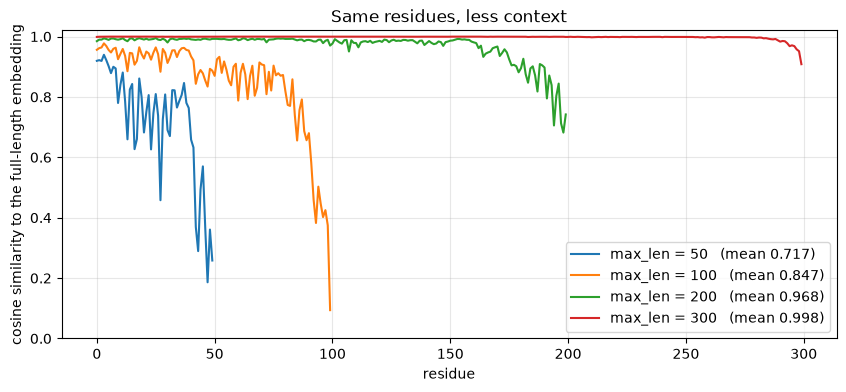

In [23]:
MAX_LENS = [50, 100, 200, 300]

trunc = {L: esm2_embed(sequence[:L]) for L in MAX_LENS}

plt.figure(figsize=(10, 4))
for L in MAX_LENS:
    s = cos(full[:L], trunc[L])
    plt.plot(s, label=f'max_len = {L}   (mean {s.mean():.3f})')
plt.xlabel('residue')
plt.ylabel('cosine similarity to the full-length embedding')
plt.title('Same residues, less context')
plt.ylim(0, 1.02)
plt.legend()
plt.grid(alpha=.3)
plt.show()

In [29]:
# The same question for the pooled, per-protein vector (as used for search / clustering)
for L in MAX_LENS:
    a, b = full[:L].mean(0), trunc[L].mean(0)
    print(f'max_len = {L:4d}   per-residue mean {cos(full[:L], trunc[L]).mean():.3f}   mean-pooled {cos_one(a, b):.3f}')

max_len =   50   per-residue mean 0.717   mean-pooled 0.830
max_len =  100   per-residue mean 0.847   mean-pooled 0.920
max_len =  200   per-residue mean 0.968   mean-pooled 0.989
max_len =  300   per-residue mean 0.998   mean-pooled 0.999


### Homework

What happens if you take `sequence[-L:]` instead and how to interpret the results?

### B. Replacing residues with X

`X` is the "unknown amino acid" token. Replacing a residue with X is the honest way to say *something is here, but we do not know what*.

The question is: how replacing a known token with `X` affect embedding of surrounding residues?

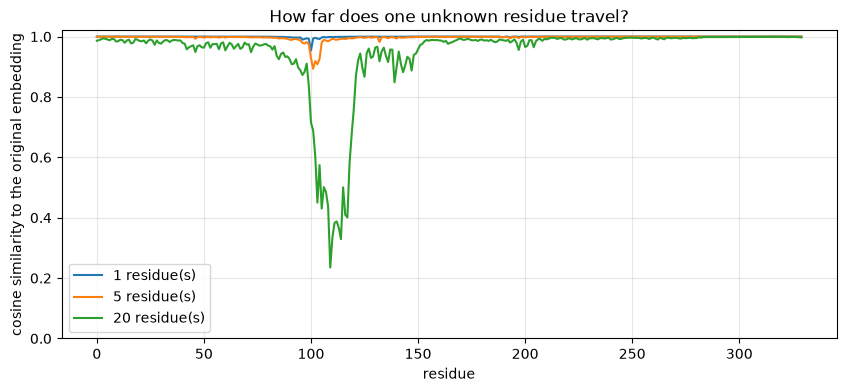

In [30]:
START = 100           # start position 
KS = [1, 5, 20]       # how many residues are replaced

def with_X(seq, start, k):
    """Replace k residues, starting at `start`, with the unknown-residue token X."""
    s = list(seq)
    for p in range(start, start + k):
        s[p] = 'X'
    return ''.join(s)

plt.figure(figsize=(10, 4))
for k in KS:
    s = cos(full, esm2_embed(with_X(sequence, START, k)))
    plt.plot(s, label=f'{k} residue(s)')
plt.xlabel('residue')
plt.ylabel('cosine similarity to the original embedding')
plt.title('How far does one unknown residue travel?')
plt.ylim(0, 1.02)
plt.legend()
plt.grid(alpha=.3)
plt.show()

### Homework

Replace the same residues with other special tokens e.g. `<mask>` and/or standard (`M`, `L` etc.) and non-standard aminoacids. What can you observe?

### C. Processing longer sequences

In [31]:
print('position embedding type :', esm2_model.config.position_embedding_type)
print('max_position_embeddings :', esm2_model.config.max_position_embeddings)
# 'rotary' -> the number above is a leftover from the config format and is NOT enforced

position embedding type : rotary
max_position_embeddings : 1026


In [32]:
long_sequence = sequence * 4           # a 4x tandem repeat, well past the 1022-residue crop
print('length:', len(long_sequence))

emb_long = esm2_embed(long_sequence)   # no error, no truncation, no warning
emb_long.shape

length: 1320


(1320, 1280)

In [33]:
s = cos(full, emb_long[:len(sequence)])
print(f'copy 1 inside the long sequence vs the same protein alone: mean cosine {s.mean():.3f}')

copy 1 inside the long sequence vs the same protein alone: mean cosine 0.644


**What to look for.** Two separate facts, and it is easy to confuse them:

1. **It runs.** No exception, no silent truncation — that is RoPE. A model with a learned
   absolute position table (ProtBert, ESM-1b) would have refused.
2. **The embeddings are different anyway**, and *not* mainly because the sequence is long:
   `sequence * 4` is a different protein — a tandem repeat — so copy 1 genuinely has a
   different context. Length extrapolation and changed context are tangled together here.

The practical warning is that beyond 1022 residues the model is working outside anything
it was trained on, and it will not tell you so. Nothing will look wrong. If you embed long
proteins, validate on a task you can score rather than trusting the numbers.

Watch the memory: attention costs O(L²), so four times the length is sixteen times the
attention matrix. Reduce the multiplier if the GPU runs out.

# 2. ESM-C

Successor of ESM-2

### Model parameters (300M or 600M)

In [24]:
# esmc_name = "esmc_300m"
esmc_name = "esmc_600m"

In [25]:
esmc_model = ESMC.from_pretrained(esmc_name).to(device).eval()

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

CPU times: user 27 s, sys: 41.6 s, total: 1min 8s
Wall time: 3min 54s


### Tokenization

In [26]:
ESMProtein(sequence=sequence)

ESMProtein(sequence='MLPDWKSSLILMAYIIIFLTGLPANLLALRAFVGRIRQPQPAPVHILLLSLTLADLLLLLLLPFKIIEAASNFRWYLPKVVCALTSFGFYSSIYCSTWLLAGISIERYLGVAFPVQYKLSRRPLYGVIAALVAWVMSFGHCTIVIIVQYLNTTEQVRSGNEITCYENFTDNQLDVVLPVRLELCLVLFFIPMAVTIFCYWRFVWIMLSQPLVGAQRRRRAVGLAVVTLLNFLVCFGPYNVSHLVGYHQRKSPWWRSIAVVFSSLNASLDPLLFYFSSSVVRRAFGRGLQVLRNQGSSLLGRRGKDTAEGTNEDRGVGQGEGMPSSDFTTE', secondary_structure=None, sasa=None, function_annotations=None, coordinates=None, plddt=None, ptm=None, pae=None, crmsd=None, globularity=None, interface_annotations=None, interface_ptm=None, pair_chains_iptm=None, output_embedding_sequence=None, output_embedding_pair_pooled=None, residue_index=None, entity_id=None, chains=None, chain_plddt=None, residue_metrics=None, potential_sequence_of_concern=False)

In [27]:
inputs = ESMProtein(sequence=sequence)
inputs = esmc_model.encode(inputs)

### Embedding generation

In [28]:
with torch.inference_mode():
    outputs = esmc_model.logits(inputs, LogitsConfig(sequence=True, return_embeddings=True))

### Outcome

In [34]:
res_esmc = outputs.embeddings[0,1:-1,:].detach().to('cpu').float().numpy()  # remove <CLS> and <EOS>
assert len(sequence) == res_esmc.shape[0]

In [35]:
np.save('res_esmc.npy', res_esmc)   # save results for future use

In [36]:
res_esmc.shape

(330, 1152)

# 3. ESM-3

Multimodal system infering based on sequence, structure and function

### Autentication

Generate token from [Hugging Face](https://huggingface.co/docs/hub/security-tokens).

In [37]:
with open('./token.txt', 'r') as file:
    token = file.readlines()
token = token[0].strip()

In [38]:
login(token=token)

## Model parameters (1.4B)

In [ ]:
esm3_model: ESM3InferenceClient = ESM3.from_pretrained("esm3-open").to(device).eval()

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 22 files:   0%|          | 0/22 [00:00<?, ?it/s]

### Tokenization

In [ ]:
inputs = ESMProtein(sequence=sequence)

CPU times: user 157 μs, sys: 0 ns, total: 157 μs
Wall time: 118 μs


## 3D structure generation

In [ ]:
if device == 'cpu':
    esm3_model = esm3_model.float()

In [ ]:
res_esm3 = esm3_model.generate(inputs, GenerationConfig(track="structure", num_steps=8))
res_esm3.to_pdb("./esm_protein.pdb")

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 12.63it/s]


CPU times: user 1.61 s, sys: 1.03 s, total: 2.64 s
Wall time: 2.33 s


/home/PawelSz/miniconda3/envs/esm_env/lib/python3.12/site-packages/esm/utils/structure/protein_complex.py:298: UserWarning: Entity ID not found in metadata, using None as default
  warnings.warn("Entity ID not found in metadata, using None as default")


### Prediction quality

#### For the whole protein

In [ ]:
float(res_esm3.ptm.detach().to('cpu')[0].float().numpy())

0.8555259108543396

#### For contact

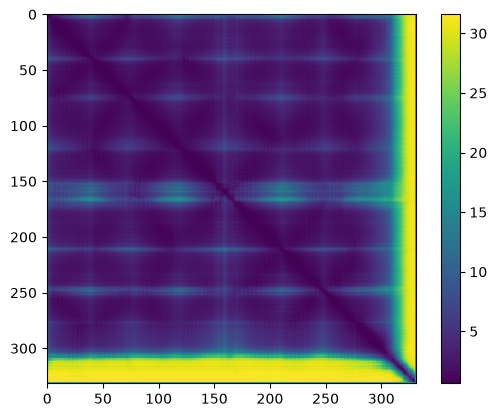

In [ ]:
plt.imshow(res_esm3.pae.detach().to('cpu')[0].float().numpy())
plt.colorbar();

#### For each residue

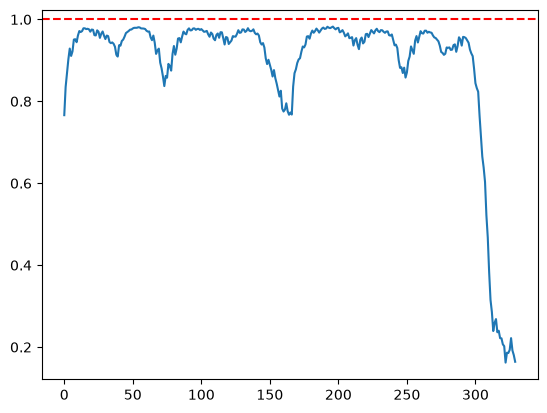

In [ ]:
plddt = res_esm3.plddt.detach().to('cpu').float().numpy()
plt.plot(plddt)
plt.axhline(y=1, ls='--', c='r')

## 3D view (py3Dmol)

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

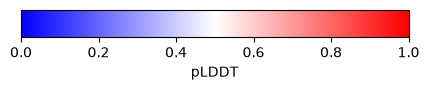

In [ ]:
import py3Dmol
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

with open('./esm_protein.pdb') as f:
    pdb_str = f.read()

# pLDDT per residue from B-factor (CA); scale: 0–1
plddt = np.array([float(l[60:66]) for l in pdb_str.splitlines()
                  if l.startswith('ATOM') and l[12:16].strip() == 'CA'])

cmap = mpl.cm.bwr  # blue / red =  low / high pLDDT
norm = mpl.colors.Normalize(vmin=0.0, vmax=1.0)

view = py3Dmol.view(width=800, height=500)
view.addModel(pdb_str, 'pdb')

# A pipe through CA, color per residue
for i, p in enumerate(plddt, start=1):  
    view.setStyle({'resi': i},
                  {'cartoon': {'style': 'trace', 'color': mpl.colors.to_hex(cmap(norm(p)))}})
view.setBackgroundColor('white')
view.zoomTo()
# eksport do html
view.write_html('esm_protein_view.html', fullpage=True)
view.show()

# Color legend
fig, ax = plt.subplots(figsize=(5, 0.35))
fig.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap=cmap),
             cax=ax, orientation='horizontal', label='pLDDT')
plt.show()

## Functional annotation

In [ ]:
function = esm3_model.generate(inputs, GenerationConfig(track="function", num_steps=8))

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 14.04it/s]


CPU times: user 882 ms, sys: 13.2 ms, total: 896 ms
Wall time: 888 ms


In [ ]:
def print_annotations(protein):
    for ann in protein.function_annotations:
        print(f"{ann.start:>3}-{ann.end:<3}  {ann.label}")

In [ ]:
print_annotations(function)

 15-23   cell communication
 15-23   communication
 15-276  coupled
 15-276  coupled receptor
 15-276  g protein
 15-276  ligase
 15-276  ligase activity
 15-21   molecular transducer
 15-23   pathway
 15-276  protein coupled
 15-23   receptor activity
 15-23   receptor signaling
 15-23   signal
 15-23   signal transduction
 15-23   signaling pathway
 15-23   signaling receptor
 15-21   transducer
 15-21   transducer activity
 15-23   transduction
 15-275  transmembrane signaling
 18-276  7tm
 24-275  forming
 18-276  heterocyclic
 18-276  heterocyclic compound
 18-276  molecule binding
 18-276  nucleotide binding
 18-276  phosphate binding
 18-276  purine
 18-276  purine nucleotide
 18-23   transmembrane transporter
 18-276  trna
 22-276  adenyl
 22-276  adenyl nucleotide
 22-275  anion binding
 22-276  compound transport
 22-275  derivative binding
 22-275  ester
 22-275  gpcr
 22-275  rhodopsin
 22-275  rhodopsin like
 22-276  substance transport
 15-276  G protein-coupled receptor,

# Excercise: multi-sequence processing

Implement sequential (sequnce by sequence) and batched processing of the multi-fasta file below. Use ESM-2 language model. Compare both outcomes.

## Input data

In [ ]:
fasta_path = "cath-superfamilies-seqs.fa"
seqs = list(SeqIO.parse(fasta_path, "fasta"))
seqs = seqs[:100]

## Sequential processing

## Batch processing

## Compare results